<a href="https://colab.research.google.com/github/gitmystuff/well-tempered-matrix/blob/main/Module_01/Module1_1_Vectors_and_Transformations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 1 Part 1: Vectors and Transformations
### Matrices that play music

Welcome! In this module we learn the first big idea of linear algebra: **a matrix is a machine that transforms things.** Instead of only drawing arrows on graph paper, we will transform *melodies* and listen to what the matrix did.

By the end of the module you will be able to:
1. Store a melody as a list of vectors (a matrix).
2. Add vectors and multiply them by numbers, and hear the result.
3. Use a 2×2 matrix to reflect, stretch, and rotate a melody.
4. Explain why playing a melody *backward and upside down* is the same as **rotating it 180°**.

## How to use this notebook

- This is a **Google Colab** notebook. It runs in the browser; nothing to install.
- Click a gray code cell and press **Shift + Enter** to run it. Run cells **in order**, top to bottom.
- Use **headphones** or speakers. A ▶ player appears under cells that make sound.
- 🎧 = listen · ✏️ = your turn · 🤔 = think before you run
- **Predict first, then listen.** Guessing what you'll hear before you hear it is where the learning happens. Being wrong is fine; it's useful.

## Setup
Run this cell once. It loads the tools and defines two helpers: `play(M)` turns a melody matrix into sound and `show(...)` draws melodies as dots. You don't need to understand the code inside yet.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

RATE = 22050  # samples per second

NOTE_NAMES = ['C','C#','D','D#','E','F','F#','G','G#','A','A#','B']
def name(p):
    """MIDI number -> note name, e.g. 60 -> C4 (middle C)."""
    p = int(round(p))
    return NOTE_NAMES[p % 12] + str(p // 12 - 1)

def freq(p):
    """MIDI number -> frequency in Hz (A4 = 69 = 440 Hz)."""
    return 440 * 2 ** ((p - 69) / 12)

def tone(p, seconds):
    """One note with a few overtones and a soft attack and decay."""
    t = np.arange(int(RATE * seconds)) / RATE
    f = freq(p)
    wave = sum(np.sin(2 * np.pi * k * f * t) / k**1.5 for k in range(1, 5))
    env = np.minimum(1, t / 0.01) * np.exp(-3 * t)
    return wave * env

def play(M, beat=0.4):
    """Play a melody matrix M. Row 0 = time (in beats), row 1 = pitch (MIDI).
    Each note lasts until the next note starts; notes at the same time form a chord."""
    M = np.asarray(M, dtype=float)
    times = M[0] - M[0].min()
    order = np.argsort(times, kind='stable')
    distinct = np.unique(np.round(times, 6))
    step = np.median(np.diff(distinct)) if len(distinct) > 1 else 1.0
    total = (times.max() + step) * beat + 0.5
    out = np.zeros(int(RATE * total))
    for i in order:
        later = distinct[distinct > times[i] + 1e-6]
        length = ((later[0] if len(later) else times[i] + step) - times[i]) * beat
        w = tone(M[1, i], length + 0.3)
        start = int(RATE * times[i] * beat)
        out[start:start + len(w)] += w[:len(out) - start]
    out /= np.abs(out).max() + 1e-9
    display(Audio(out, rate=RATE))

def show(*melodies, labels=None):
    """Draw one or more melodies as dots: time across, pitch up."""
    plt.figure(figsize=(9, 3.5))
    for k, M in enumerate(melodies):
        M = np.asarray(M, dtype=float)
        lab = labels[k] if labels else None
        plt.plot(M[0], M[1], 'o-', alpha=0.75, label=lab)
    plt.xlabel('time (beats)'); plt.ylabel('pitch (MIDI number)')
    plt.grid(alpha=0.3)
    if labels: plt.legend()
    plt.show()

print("Ready! Middle C is", 60, "=", name(60), "at", round(freq(60), 1), "Hz")

Ready! Middle C is 60 = C4 at 261.6 Hz


---
# Week 1 · A note is a vector

A **vector** is just an ordered list of numbers. A musical note can be described by two numbers:

$$\text{note} = \begin{bmatrix} \text{time} \\ \text{pitch} \end{bmatrix}$$

- **time** = when the note starts, counted in beats
- **pitch** = a MIDI number: middle C is 60, and each step up is one piano key (a half step). 12 steps = one octave.

So the vector $\begin{bmatrix} 3 \\ 67 \end{bmatrix}$ means "play G4 on beat 3."

NOTE: MIDI stands for Musical Instrument Digital Interface. It’s a standard, created in 1983, that lets electronic instruments and computers talk to each other about music. MIDI doesn’t send sound. It sends instructions, such as “play this key, this hard, for this long.” Each key on a piano gets a number from 0 to 127. Middle C is 60, each step up or down is one piano key (a half step), and 12 steps make one octave, so the next C up is 72. Using numbers instead of letter names lets us do math with pitches: adding 7 to a note raises it by a musical fifth, and the computer can turn any MIDI number into its frequency in hertz (vibrations per second).

In [ ]:
note = np.array([3, 67])
print("time =", note[0], " pitch =", note[1], "=", name(note[1]))

time = 3  pitch = 67 = G4


### A melody is a matrix
Line up the note vectors side by side as **columns** and you get a **matrix** with 2 rows. Here is the opening of Beethoven's *Ode to Joy*:

Row 0 is the times and row 1 is the pitches. Each column is one note.

In [ ]:
pitches = [64, 64, 65, 67, 67, 65, 64, 62, 60, 60, 62, 64, 64, 62, 62]  # E E F G G F E D C C D E E D D
times   = list(range(len(pitches)))
ode = np.array([times, pitches])

print("Shape of the matrix:", ode.shape, "(2 rows, one column per note)")
print(ode)
print("Notes:", [name(p) for p in ode[1]])

Shape of the matrix: (2, 15) (2 rows, one column per note)
[[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
 [64 64 65 67 67 65 64 62 60 60 62 64 64 62 62]]
Notes: ['E4', 'E4', 'F4', 'G4', 'G4', 'F4', 'E4', 'D4', 'C4', 'C4', 'D4', 'E4', 'E4', 'D4', 'D4']


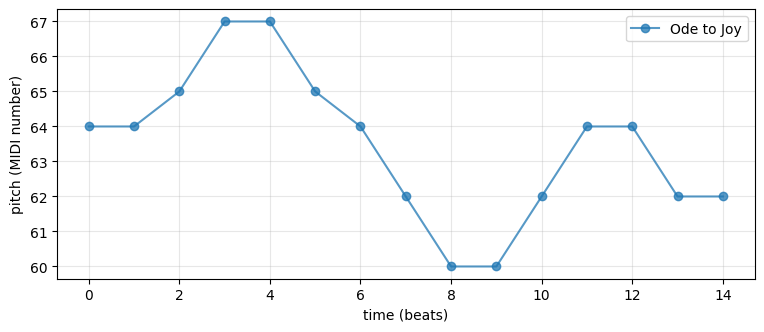

In [ ]:
show(ode, labels=['Ode to Joy'])
play(ode)  # 🎧

### Vectors as arrows
A vector can also be pictured as an **arrow** from the origin. The arrows below are the first three notes. Notice the pitch numbers are big (around 64) compared with the times (0–2), so the arrows point almost straight up.

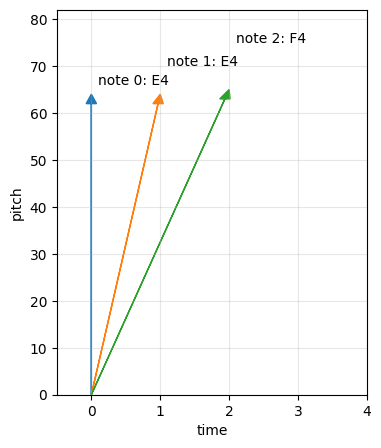

In [ ]:
plt.figure(figsize=(4, 5))
for i in range(3):
    plt.arrow(0, 0, ode[0, i], ode[1, i], head_width=0.15, head_length=2,
              length_includes_head=True, color=f'C{i}')
    plt.text(ode[0, i] + 0.1, ode[1, i] + 2 + 4 * i, f'note {i}: {name(ode[1, i])}')
plt.xlim(-0.5, 4); plt.ylim(0, 82)
plt.xlabel('time'); plt.ylabel('pitch'); plt.grid(alpha=0.3); plt.show()

### ✏️ Your turn: write your own melody
Replace the numbers below with a short melody of your own (8 notes or so). Use the piano numbers: C=60, D=62, E=64, F=65, G=67, A=69, B=71, C=72.

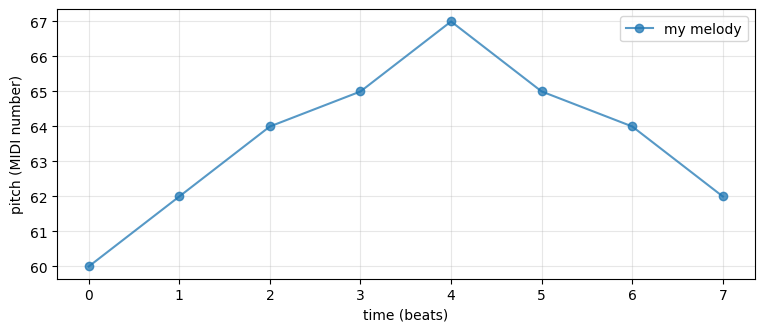

In [ ]:
my_pitches = [60, 62, 64, 65, 67, 65, 64, 62]   # change me!
mine = np.array([range(len(my_pitches)), my_pitches])
show(mine, labels=['my melody'])
play(mine)

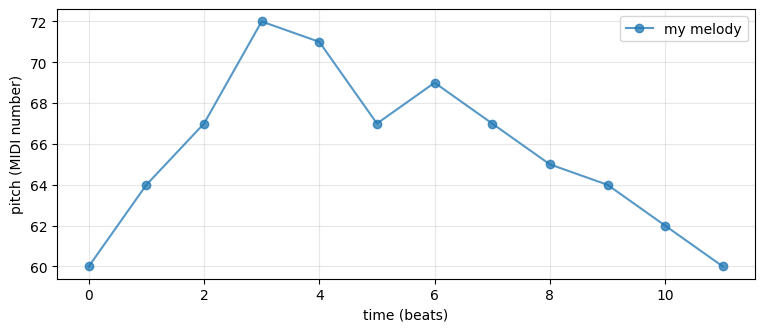

In [ ]:
# sample example
# My melody: up the C major chord, then step back down to C
#              C4  E4  G4  C5  B4  G4  A4  G4  F4  E4  D4  C4
my_pitches = [60, 64, 67, 72, 71, 67, 69, 67, 65, 64, 62, 60]
mine = np.array([range(len(my_pitches)), my_pitches])
show(mine, labels=['my melody'])
play(mine)

---
# Week 2 · Adding vectors and scaling them

Two basic operations with vectors:

- **Addition:** add matching entries. $\begin{bmatrix} 3 \\ 64 \end{bmatrix} + \begin{bmatrix} 0 \\ 7 \end{bmatrix} = \begin{bmatrix} 3 \\ 71 \end{bmatrix}$
- **Scalar multiplication:** multiply every entry by one number. $2 \begin{bmatrix} 3 \\ 64 \end{bmatrix} = \begin{bmatrix} 6 \\ 128 \end{bmatrix}$

### Transposing = adding a vector
Adding $\begin{bmatrix} 0 \\ 7 \end{bmatrix}$ to every note moves every pitch up 7 half steps and leaves the time alone. Musicians call this **transposing**.

🤔 *Predict: will it sound like the same tune? Higher or lower?*

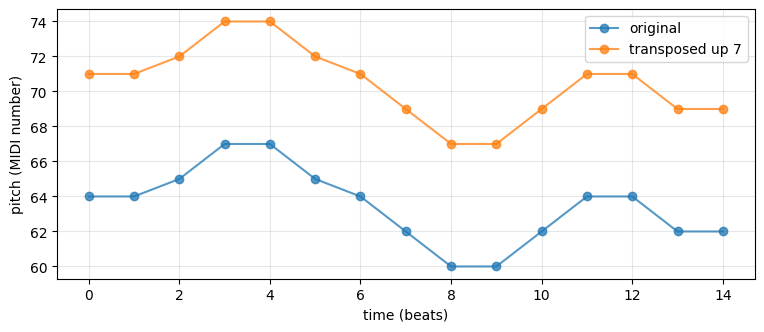

In [ ]:
shift = np.array([[0], [7]])     # a column vector
ode_up = ode + shift             # numpy adds it to every column
show(ode, ode_up, labels=['original', 'transposed up 7'])
play(ode_up)  # 🎧

### A chord is a sum of waves
Sound itself is a vector: a long list of air-pressure numbers, 22,050 per second. Playing notes **together** means **adding** their vectors. Below, three waves are added to make a C major chord.

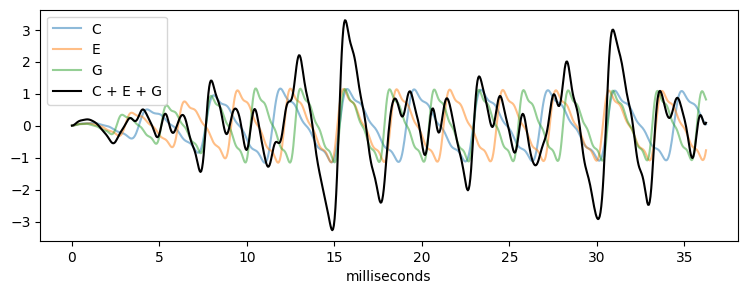

In [ ]:
C = tone(60, 2); E = tone(64, 2); G = tone(67, 2)
chord = C + E + G                          # vector addition!

t = np.arange(800) / RATE * 1000
plt.figure(figsize=(9, 3))
plt.plot(t, C[:800], alpha=0.5, label='C'); plt.plot(t, E[:800], alpha=0.5, label='E')
plt.plot(t, G[:800], alpha=0.5, label='G'); plt.plot(t, chord[:800], 'k', label='C + E + G')
plt.xlabel('milliseconds'); plt.legend(); plt.show()
display(Audio(chord / np.abs(chord).max(), rate=RATE))   # 🎧

### ✏️ Your turn
1. A **minor** chord lowers the middle note by one half step. Make a C minor chord (60, 63, 67) and listen. What would a **major** chord be?
2. Transpose *your* melody from earlier down an octave. Which vector do you add?

In [ ]:
# 1. C minor chord


# 2. Your melody, down an octave

minor


Major


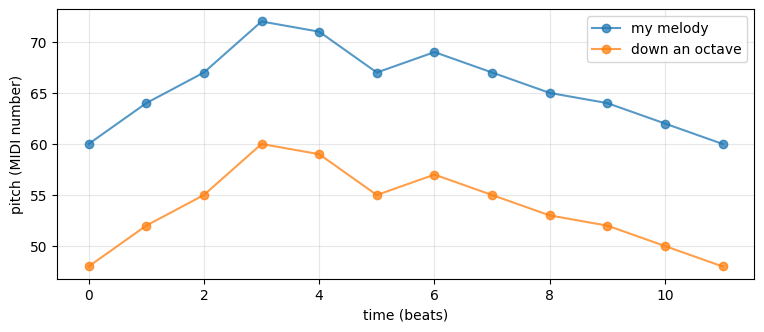

In [ ]:
# completed example
# 1. C minor chord
#    C4 = 60, E-flat4 = 63, G4 = 67
Cm = tone(60, 2) + tone(63, 2) + tone(67, 2)        # add the three waves
print("minor")
display(Audio(Cm / np.abs(Cm).max(), rate=RATE))     # 🎧

# Compare it with C major (60, 64, 67)
CM = tone(60, 2) + tone(64, 2) + tone(67, 2)
print("Major")
display(Audio(CM / np.abs(CM).max(), rate=RATE))     # 🎧


# 2. Your melody, down an octave
down = np.array([[0], [-12]])     # time +0, pitch −12
mine_low = mine + down
show(mine, mine_low, labels=['my melody', 'down an octave'])
play(mine_low)                    # 🎧

---
# Week 3 · Matrices transform melodies

Now the main event. A 2×2 matrix **multiplies** a vector and produces a new vector:

$$\begin{bmatrix} a & b \\ c & d \end{bmatrix}\begin{bmatrix} x \\ y \end{bmatrix} = \begin{bmatrix} a x + b y \\ c x + d y \end{bmatrix}$$

Multiply the matrix by the *whole melody* and it transforms every note at once. In Python, matrix multiplication is written `@`.

**One small trick.** Matrices stretch and flip things around the **origin** (0, 0). Our melody sits far from the origin (pitches near 64), so we first move the melody so its center is at (0, 0), then transform, then move it back. The helper below does that.

Note: Something not clear? Please consult with AI first and then... I am happy to help.

In [ ]:
def transform(A, M):
    """Apply 2x2 matrix A to melody M, centered on the melody's middle."""
    M = np.asarray(M, dtype=float)
    center = M.mean(axis=1, keepdims=True)
    return A @ (M - center) + center

### Stretching time
$$S = \begin{bmatrix} 2 & 0 \\ 0 & 1 \end{bmatrix}$$

🤔 *The 2 is in the time row and the 1 is in the pitch row. Predict what happens before you listen.*

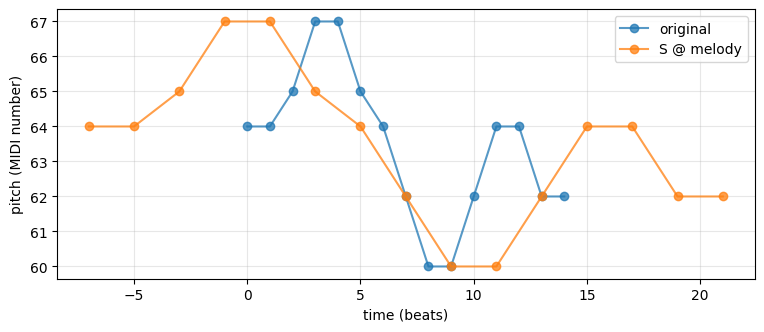

In [ ]:
S = np.array([[2, 0],
              [0, 1]])
slow = transform(S, ode)
show(ode, slow, labels=['original', 'S @ melody'])
play(slow)  # 🎧

Did the tempo change? The `play` helper keeps the beat steady, so stretching time makes each note *longer*. Now try **squishing** pitch instead:
$$P = \begin{bmatrix} 1 & 0 \\ 0 & 0.5 \end{bmatrix}$$

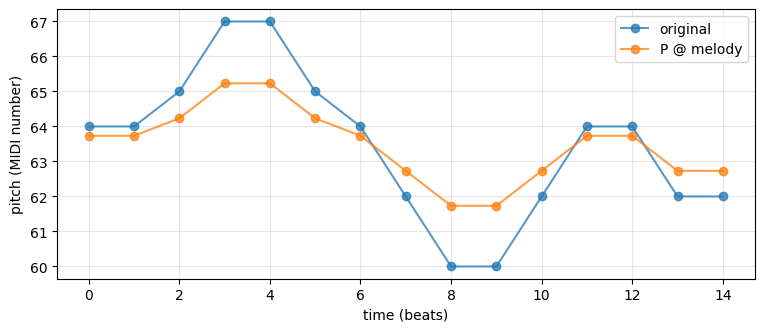

In [ ]:
P = np.array([[1, 0],
              [0, 0.5]])
flat = transform(P, ode)
show(ode, flat, labels=['original', 'P @ melody'])
play(flat)  # 🎧  (pitches between piano keys are allowed!)

### ✏️ Your turn
Before running each one, write down your prediction in a comment.
1. What does $\begin{bmatrix} 1 & 0 \\ 0 & 2 \end{bmatrix}$ do to the melody?
2. What does $\begin{bmatrix} 1 & 0 \\ 0 & 0 \end{bmatrix}$ do? (A very strange melody!)

In [ ]:
# Prediction 1:
# Prediction 2:

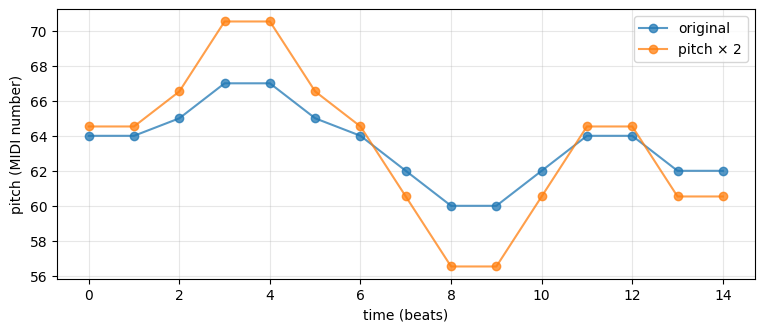

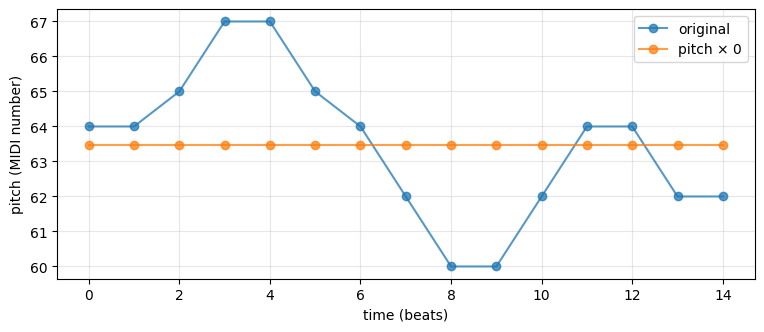

Original: [64 64 65 67 67 65 64 62 60 60 62 64 64 62 62]
Pitch × 2: [64.5 64.5 66.5 70.5 70.5 66.5 64.5 60.5 56.5 56.5 60.5 64.5 64.5 60.5
 60.5]
Pitch × 0: [63.5 63.5 63.5 63.5 63.5 63.5 63.5 63.5 63.5 63.5 63.5 63.5 63.5 63.5
 63.5]


In [ ]:
# completed example
# Prediction 1: The top row [1 0] leaves time alone. The bottom row [0 2]
#   doubles the pitch, measured from the melody's middle. Every step up or
#   down should become twice as big, so the tune keeps its shape but sounds
#   more dramatic, with bigger jumps.
# Prediction 2: The bottom row [0 0] multiplies every pitch by zero, so
#   every note should land on the same middle pitch. The rhythm stays, but
#   the tune disappears: one note repeated 15 times.

M1 = np.array([[1, 0],
               [0, 2]])
tall = transform(M1, ode)
show(ode, tall, labels=['original', 'pitch × 2'])
play(tall)    # 🎧

M2 = np.array([[1, 0],
               [0, 0]])
squashed = transform(M2, ode)
show(ode, squashed, labels=['original', 'pitch × 0'])
play(squashed)    # 🎧

# Check the actual pitches
print("Original:", ode[1])
print("Pitch × 2:", np.round(tall[1], 1))
print("Pitch × 0:", np.round(squashed[1], 1))

---
# Week 4 · Reflections, rotations, and composers

Composers have used these transformations for centuries, especially Bach and, later, Schoenberg.

| Musical name | What happens | Matrix |
|---|---|---|
| **Inversion** | melody upside down | $I = \begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix}$ |
| **Retrograde** | melody backward | $R = \begin{bmatrix} -1 & 0 \\ 0 & 1 \end{bmatrix}$ |

Both are **reflections**: one flips across a horizontal line, the other across a vertical line.

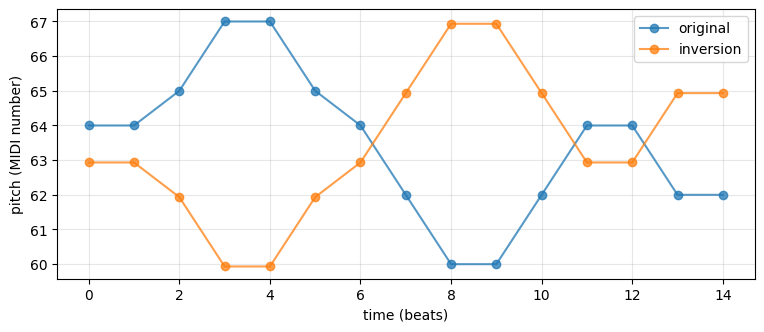

In [ ]:
I = np.array([[1,  0],
              [0, -1]])
R = np.array([[-1, 0],
              [ 0, 1]])

inv = transform(I, ode)
show(ode, inv, labels=['original', 'inversion'])
play(inv)  # 🎧

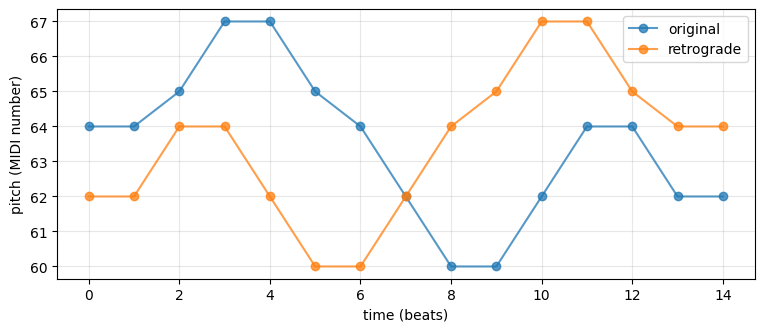

In [ ]:
retro = transform(R, ode)
show(ode, retro, labels=['original', 'retrograde'])
play(retro)  # 🎧

### Doing two transformations in a row = multiplying matrices
To play a melody **backward AND upside down** (called *retrograde inversion*), apply $I$ and then $R$. That is the same as multiplying the matrices first:
$$R\,I = \begin{bmatrix} -1 & 0 \\ 0 & 1 \end{bmatrix}\begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix} = \;?$$

🤔 *Work out $R\,I$ by hand first, then check below.*

R @ I =
 [[-1  0]
 [ 0 -1]]


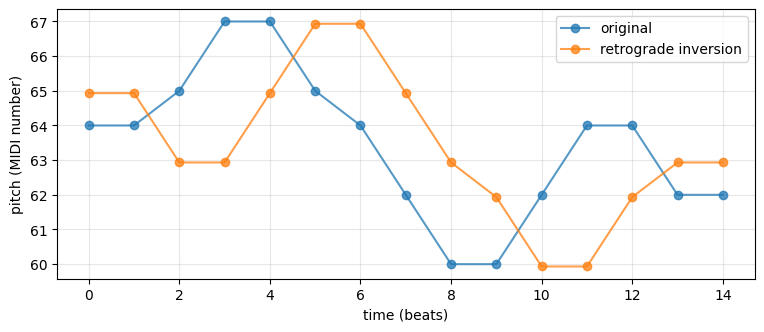

In [ ]:
RI = R @ I
print("R @ I =\n", RI)
ri = transform(RI, ode)
show(ode, ri, labels=['original', 'retrograde inversion'])
play(ri)  # 🎧

### The surprise: it's a rotation
The general **rotation matrix** turns every point by an angle $\theta$:
$$\text{Rot}(\theta) = \begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix}$$

Compare $R\,I$ with a rotation by 180°.

In [ ]:
def Rot(degrees):
    th = np.radians(degrees)
    return np.array([[np.cos(th), -np.sin(th)],
                     [np.sin(th),  np.cos(th)]])

print("Rotation by 180 degrees:\n", np.round(Rot(180), 10))
print("Same as R @ I?", np.allclose(Rot(180), R @ I))

Rotation by 180 degrees:
 [[-1. -0.]
 [ 0. -1.]]
Same as R @ I? True


**Backward + upside down = turning the melody halfway around.** Two reflections make a rotation. Composers knew the musical fact; linear algebra explains *why*.

### ✏️ Challenges for the Week 4 meeting
1. Does order matter? Compute `I @ R` and compare with `R @ I`. Then try `S @ I` versus `I @ S` from Week 3. Find a pair where **order changes the sound**.
2. Apply `Rot(90)` to the melody. Time and pitch trade places. Is it still music? Describe what you hear.
3. Try a small rotation like `Rot(10)`. Why does it sound like the melody keeps sliding?
4. Apply $I$ twice. What do you get? What matrix "undoes" $I$?
5. **Bring to the meeting:** your favorite transformed melody and the matrix that made it.

In [ ]:
# Challenge workspace

I @ R =
 [[-1  0]
 [ 0 -1]]
R @ I =
 [[-1  0]
 [ 0 -1]]
S @ I =
 [[ 2  0]
 [ 0 -1]]
I @ S =
 [[ 2  0]
 [ 0 -1]]
I @ Rot(90) =
 [[ 0. -1.]
 [-1. -0.]]
Rot(90) @ I =
 [[ 0.  1.]
 [ 1. -0.]]


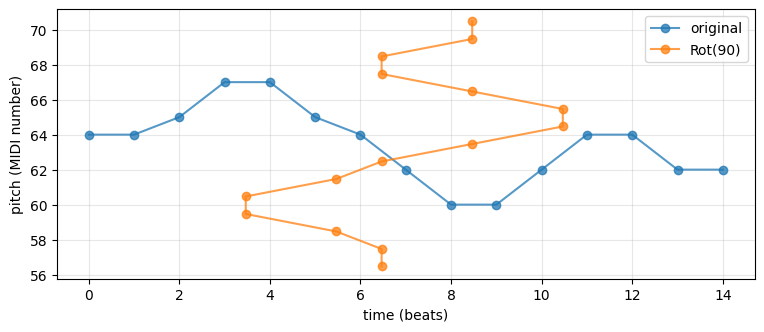

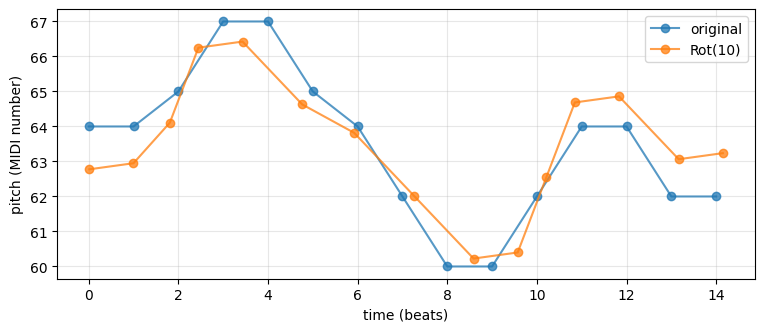

I @ I =
 [[1 0]
 [0 1]]
Inverse of I =
 [[ 1.  0.]
 [-0. -1.]]


In [ ]:
# completed example
# ---- Challenge 1: Does order matter? ----
print("I @ R =\n", I @ R)
print("R @ I =\n", R @ I)          # same! diagonal matrices commute
print("S @ I =\n", S @ I)
print("I @ S =\n", I @ S)          # same again

# A pair where order DOES matter
A = I @ Rot(90)
B = Rot(90) @ I
print("I @ Rot(90) =\n", np.round(A, 3))
print("Rot(90) @ I =\n", np.round(B, 3))     # different!
play(transform(A, ode))   # 🎧
play(transform(B, ode))   # 🎧 sounds different

# ---- Challenge 2: Rotate 90 degrees ----
r90 = transform(Rot(90), ode)
show(ode, r90, labels=['original', 'Rot(90)'])
play(r90)   # 🎧

# ---- Challenge 3: A small rotation ----
r10 = transform(Rot(10), ode)
show(ode, r10, labels=['original', 'Rot(10)'])
play(r10)   # 🎧

# ---- Challenge 4: Apply I twice ----
print("I @ I =\n", I @ I)
print("Inverse of I =\n", np.linalg.inv(I))
play(transform(I @ I, ode))   # 🎧 the original melody returns

In [ ]:
# def play(M, beat=0.4, title=None, graph=True):
def play(M, beat=0.4, title=None, graph=True, color='C1'):
    """Play a melody matrix M. Row 0 = time (in beats), row 1 = pitch (MIDI).
    Each note lasts until the next note starts; notes at the same time form a chord.
    Also draws the melody, in playing order, right above the player."""
    M = np.asarray(M, dtype=float)
    times = M[0] - M[0].min()
    order = np.lexsort((M[1], times))
    if graph:
        plt.figure(figsize=(9, 2.5))
        # plt.plot(times[order], M[1][order], 'o-', alpha=0.75, color='C1')
        plt.plot(times[order], M[1][order], 'o-', alpha=0.75, color=color)
        plt.xlabel('time (beats)'); plt.ylabel('pitch (MIDI)')
        plt.grid(alpha=0.3)
        if title: plt.title(title)
        plt.show()
    distinct = np.unique(np.round(times, 6))
    step = np.median(np.diff(distinct)) if len(distinct) > 1 else 1.0
    total = (times.max() + step) * beat + 0.5
    out = np.zeros(int(RATE * total))
    for i in order:
        later = distinct[distinct > times[i] + 1e-6]
        length = ((later[0] if len(later) else times[i] + step) - times[i]) * beat
        w = tone(M[1, i], length + 0.3)
        start = int(RATE * times[i] * beat)
        out[start:start + len(w)] += w[:len(out) - start]
    out /= np.abs(out).max() + 1e-9
    display(Audio(out, rate=RATE))

help(play)

Help on function play in module __main__:

play(M, beat=0.4, title=None, graph=True, color='C1')
    Play a melody matrix M. Row 0 = time (in beats), row 1 = pitch (MIDI).
    Each note lasts until the next note starts; notes at the same time form a chord.
    Also draws the melody, in playing order, right above the player.



<IPython.core.display.Javascript object>

I @ R =
 [[-1  0]
 [ 0 -1]]
R @ I =
 [[-1  0]
 [ 0 -1]]
S @ I =
 [[ 2  0]
 [ 0 -1]]
I @ S =
 [[ 2  0]
 [ 0 -1]]
I @ Rot(90) =
 [[ 0. -1.]
 [-1. -0.]]
Rot(90) @ I =
 [[ 0.  1.]
 [ 1. -0.]]


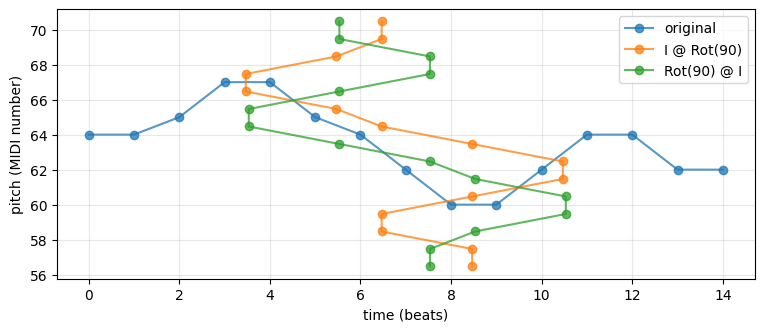

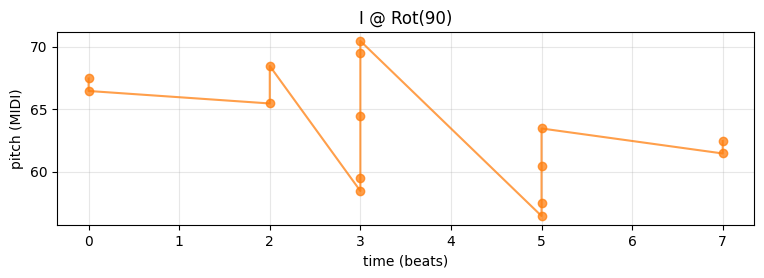

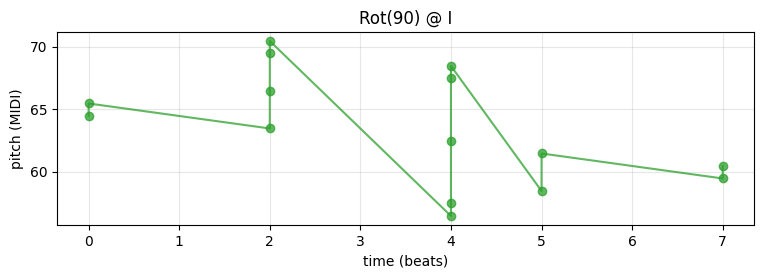

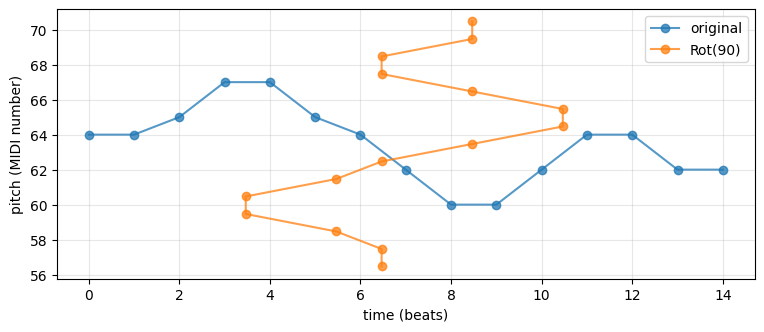

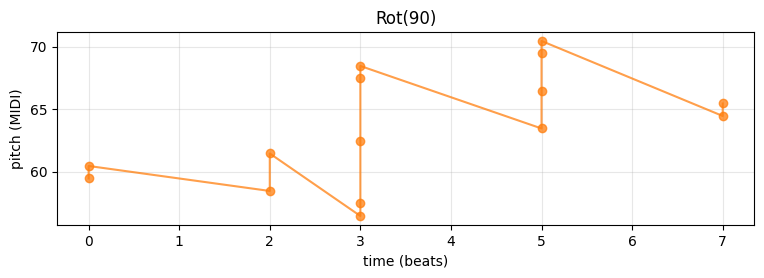

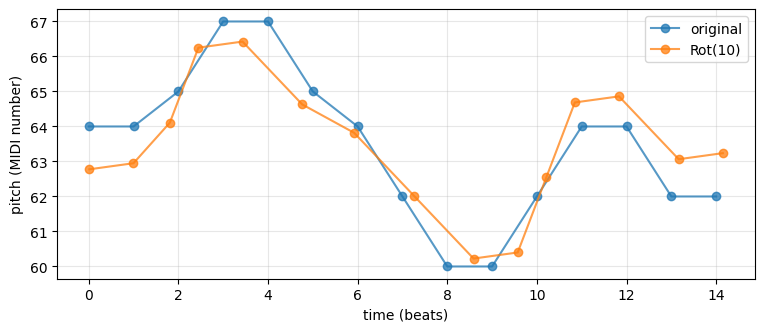

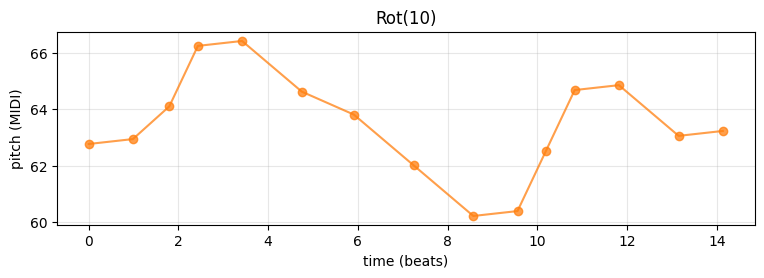

I @ I =
 [[1 0]
 [0 1]]
Inverse of I =
 [[ 1.  0.]
 [-0. -1.]]


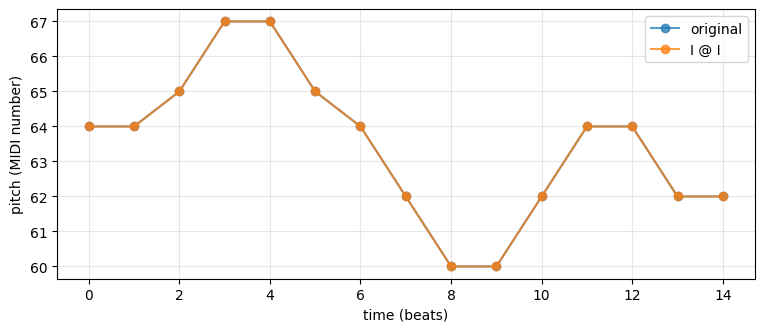

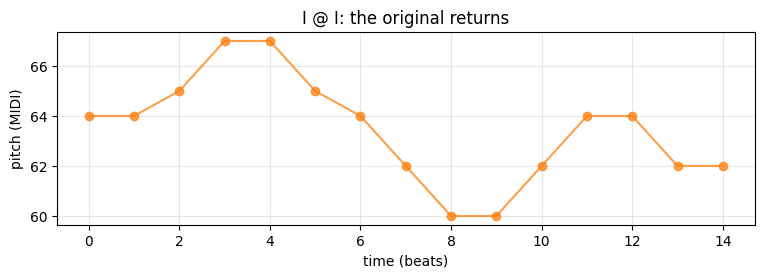

In [ ]:
# completed example
from google.colab import output
output.no_vertical_scroll()
# ---- Challenge 1: Does order matter? ----
print("I @ R =\n", I @ R)
print("R @ I =\n", R @ I)          # same! diagonal matrices commute
print("S @ I =\n", S @ I)
print("I @ S =\n", I @ S)          # same again

# A pair where order DOES matter
A = I @ Rot(90)
B = Rot(90) @ I
print("I @ Rot(90) =\n", np.round(A, 3))
print("Rot(90) @ I =\n", np.round(B, 3))     # different!

flip_then_turn = transform(A, ode)
turn_then_flip = transform(B, ode)
show(ode, flip_then_turn, turn_then_flip,
     labels=['original', 'I @ Rot(90)', 'Rot(90) @ I'])
# play(flip_then_turn, title='I @ Rot(90)')    # 🎧
# play(turn_then_flip, title='Rot(90) @ I')    # 🎧 sounds different
play(flip_then_turn, title='I @ Rot(90)', color='C1')   # orange, like the comparison graph
play(turn_then_flip, title='Rot(90) @ I', color='C2')   # green, like the comparison graph

# ---- Challenge 2: Rotate 90 degrees ----
r90 = transform(Rot(90), ode)
show(ode, r90, labels=['original', 'Rot(90)'])
play(r90, title='Rot(90)')    # 🎧

# ---- Challenge 3: A small rotation ----
r10 = transform(Rot(10), ode)
show(ode, r10, labels=['original', 'Rot(10)'])
play(r10, title='Rot(10)')    # 🎧

# ---- Challenge 4: Apply I twice ----
print("I @ I =\n", I @ I)
print("Inverse of I =\n", np.linalg.inv(I))
back = transform(I @ I, ode)
show(ode, back, labels=['original', 'I @ I'])
play(back, title='I @ I: the original returns')    # 🎧


## Summary: Matrix theory through music

In this module, a melody was our data. Every idea below is general matrix theory, with the music as the example.

### 1. Vectors and matrices
A **vector** in $\mathbb{R}^2$ is an ordered pair of numbers, written as a column. In this module, each note was a vector, with its time on top and its pitch below:
$$\mathbf{v} = \begin{bmatrix} x \\ y \end{bmatrix} = \begin{bmatrix} \text{when played} \\ \text{pitch (MIDI number)} \end{bmatrix}$$

*Example:* $\begin{bmatrix} 3 \\ 67 \end{bmatrix}$ means "play G4 (67) at the time indicated (3)."

Placing $n$ vectors side by side as columns forms a $2 \times n$ **matrix**. A melody is a matrix with one column per note:
$$M = \begin{bmatrix} \mathbf{v}_1 & \mathbf{v}_2 & \cdots & \mathbf{v}_n \end{bmatrix}$$

*Example:* the first five notes of *Ode to Joy* (E E F G G):
$$M = \begin{bmatrix} 0 & 1 & 2 & 3 & 4 \\ 64 & 64 & 65 & 67 & 67 \end{bmatrix}$$

*Compare the orignal melody and then the transform using Rot(10)*:

**Original melody**

$M = \begin{bmatrix} 0 & 1 & 2 & 3 & 4 & 5 & 6 & 7 & 8 & 9 & 10 & 11 & 12 & 13 & 14 \\ 64 & 64 & 65 & 67 & 67 & 65 & 64 & 62 & 60 & 60 & 62 & 64 & 64 & 62 & 62 \end{bmatrix}$

**After $\text{Rot}(10^\circ)$**
$M' = \begin{bmatrix} 0.01 & 1.00 & 1.81 & 2.45 & 3.43 & 4.76 & 5.92 & 7.25 & 8.59 & 9.57 & 10.21 & 10.85 & 11.83 & 13.16 & 14.15 \\ 62.78 & 62.95 & 64.11 & 66.25 & 66.43 & 64.63 & 63.82 & 62.02 & 60.23 & 60.40 & 62.54 & 64.69 & 64.86 & 63.06 & 63.24 \end{bmatrix}$

### 2. Vector addition and scalar multiplication
Vectors add entry by entry:
$$\begin{bmatrix} x \\ y \end{bmatrix} + \begin{bmatrix} a \\ b \end{bmatrix} = \begin{bmatrix} x + a \\ y + b \end{bmatrix}$$

*Example: transposing.* Adding $\begin{bmatrix} 0 \\ 7 \end{bmatrix}$ to every note leaves the time alone and raises every pitch by 7 half steps:
$$\begin{bmatrix} 3 \\ 67 \end{bmatrix} + \begin{bmatrix} 0 \\ 7 \end{bmatrix} = \begin{bmatrix} 3 \\ 74 \end{bmatrix}$$
Adding $\begin{bmatrix} 0 \\ -12 \end{bmatrix}$ moves the melody down one octave.

Adding the same vector to every point is a **translation** (a shift). A translation moves the origin, so it is *not* a linear transformation.

A **scalar** (a single number) multiplies every entry: $c\begin{bmatrix} x \\ y \end{bmatrix} = \begin{bmatrix} cx \\ cy \end{bmatrix}$.

*Example: a chord.* A sound is also a vector, a long list of air-pressure values. Playing C, E, and G together adds their vectors: $\text{chord} = \mathbf{C} + \mathbf{E} + \mathbf{G}$.

### 3. A matrix is a transformation
A $2 \times 2$ matrix $A$ transforms a vector by **matrix–vector multiplication**. Each row of $A$ produces one entry of the result:
$$A\mathbf{v} = \begin{bmatrix} a & b \\ c & d \end{bmatrix}\begin{bmatrix} x \\ y \end{bmatrix} = \begin{bmatrix} ax + by \\ cx + dy \end{bmatrix}$$

*Example:* the stretch $S$ moves a note from beat 3 to beat 6 and keeps its pitch:
$$S\mathbf{v} = \begin{bmatrix} 2 & 0 \\ 0 & 1 \end{bmatrix}\begin{bmatrix} 3 \\ 67 \end{bmatrix} = \begin{bmatrix} 2 \cdot 3 + 0 \cdot 67 \\ 0 \cdot 3 + 1 \cdot 67 \end{bmatrix} = \begin{bmatrix} 6 \\ 67 \end{bmatrix}$$

Multiplying $A$ by the melody matrix transforms every note at once:
$$A M = \begin{bmatrix} A\mathbf{v}_1 & A\mathbf{v}_2 & \cdots & A\mathbf{v}_n \end{bmatrix}$$

**Centering.** Linear transformations always keep the origin $\begin{bmatrix} 0 \\ 0 \end{bmatrix}$ fixed, but our melody sits far from the origin (pitches near 64). So we shifted the melody's center $\mathbf{c}$ to the origin, transformed, and shifted back:
$$\mathbf{v}' = A(\mathbf{v} - \mathbf{c}) + \mathbf{c}$$
For *Ode to Joy*, the center is about $\mathbf{c} = \begin{bmatrix} 7 \\ 63.47 \end{bmatrix}$: the middle beat and the average pitch.

### 4. The transformations we used

Note: leap means the interval between each step

| Transformation | Matrix | What it did to the melody |
|---|---|---|
| Stretch time by 2 | $S = \begin{bmatrix} 2 & 0 \\ 0 & 1 \end{bmatrix}$ | each note lasts twice as long |
| Stretch pitch by 2 | $\begin{bmatrix} 1 & 0 \\ 0 & 2 \end{bmatrix}$ | every leap doubles in size |
| Compress pitch by $\tfrac{1}{2}$ | $\begin{bmatrix} 1 & 0 \\ 0 & \tfrac{1}{2} \end{bmatrix}$ | every leap is half as big |
| Collapse pitch | $\begin{bmatrix} 1 & 0 \\ 0 & 0 \end{bmatrix}$ | every note becomes the same pitch |
| Reflect: $y \to -y$ | $I = \begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix}$ | **inversion**: melody upside down |
| Reflect: $x \to -x$ | $R = \begin{bmatrix} -1 & 0 \\ 0 & 1 \end{bmatrix}$ | **retrograde**: melody backward |
| Rotate by $\theta$ | $\text{Rot}(\theta) = \begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix}$ | mixes time and pitch together |

**Singular matrices.** The collapsing matrix sends every pitch to the same value, so the original tune cannot be recovered. A matrix that loses information like this is called **singular**. Its determinant is zero:
$$\det\begin{bmatrix} a & b \\ c & d \end{bmatrix} = ad - bc, \qquad \det\begin{bmatrix} 1 & 0 \\ 0 & 0 \end{bmatrix} = 1 \cdot 0 - 0 \cdot 0 = 0$$

Note: Determinant tells us how much a matrix stretches or shrinks area (if terms are new, don't worry, we will be reusing terms constantly so they will become second nature)

**Rotation by 90°.** With $\cos 90^\circ = 0$ and $\sin 90^\circ = 1$:
$$\text{Rot}(90^\circ)\begin{bmatrix} x \\ y \end{bmatrix} = \begin{bmatrix} 0 & -1 \\ 1 & 0 \end{bmatrix}\begin{bmatrix} x \\ y \end{bmatrix} = \begin{bmatrix} -y \\ x \end{bmatrix}$$
Time and pitch trade places: a note that was *high* becomes *early*, and a note that was *early* becomes *low*. Notes that shared a pitch now share a time, so the melody turned into chords.

### 5. Composition is matrix multiplication
Applying $B$ first and then $A$ is the same as applying the single matrix $AB$:
$$A(B\mathbf{v}) = (AB)\mathbf{v}$$
The matrix written on the **right** acts **first**.

*Example: retrograde inversion.* Turning the melody upside down ($I$) and then playing it backward ($R$):
$$RI = \begin{bmatrix} -1 & 0 \\ 0 & 1 \end{bmatrix}\begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix} = \begin{bmatrix} -1 & 0 \\ 0 & -1 \end{bmatrix} = \text{Rot}(180^\circ)$$
Two reflections make a rotation: backward and upside down is the same as turning the melody halfway around.

### 6. Order usually matters
Matrix multiplication is generally **not commutative**: $AB \neq BA$.

*Example:* flipping the melody and rotating it by $90^\circ$, in two different orders:
$$I \, \text{Rot}(90^\circ) = \begin{bmatrix} 0 & -1 \\ -1 & 0 \end{bmatrix}, \qquad \text{Rot}(90^\circ) \, I = \begin{bmatrix} 0 & 1 \\ 1 & 0 \end{bmatrix}$$
The two results differ by a factor of $-1$ (a $180^\circ$ rotation), and they sound different.

**Exception:** **diagonal matrices** (nonzero entries only on the main diagonal) always commute, which is why $IR = RI$ and $SI = IS$:
$$\begin{bmatrix} a & 0 \\ 0 & d \end{bmatrix}\begin{bmatrix} p & 0 \\ 0 & s \end{bmatrix} = \begin{bmatrix} ap & 0 \\ 0 & ds \end{bmatrix} = \begin{bmatrix} p & 0 \\ 0 & s \end{bmatrix}\begin{bmatrix} a & 0 \\ 0 & d \end{bmatrix}$$
Musically, each diagonal matrix changes only time or only pitch, so it doesn't matter which one goes first.

### 7. Identity and inverses
The **identity matrix** leaves every vector unchanged, like multiplying a number by 1. (We write it as $\mathrm{Id}$, since $I$ already names our inversion.)
$$\mathrm{Id} = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}, \qquad \mathrm{Id}\,\mathbf{v} = \mathbf{v}$$
Musically, $\mathrm{Id}$ plays the melody exactly as written.

The **inverse** $A^{-1}$ undoes $A$:
$$A A^{-1} = A^{-1} A = \mathrm{Id}$$

*Example:* turning the melody upside down twice brings back the original, so the inversion is its own inverse:
$$I I = \begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix}\begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix} = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix} = \mathrm{Id}, \qquad \text{so } I^{-1} = I$$

### Key ideas
- A matrix is a **machine that transforms vectors**; a melody is a matrix of note vectors.
- Each row of the matrix computes one entry of the output.
- Doing one transformation after another **multiplies** the matrices, and the order usually matters.
- Two reflections combine into a rotation: retrograde inversion is a $180^\circ$ turn.
- A matrix with determinant $0$ destroys information and has no inverse.

## Using AI as a tutor

We will be revisiting all of these terms frequently. The seed is being planted and will soon become second nature. Till then, try AI:

Good ways to use an AI assistant with this notebook:
- "Explain matrix multiplication with a 2×2 example, then give me one to try myself."
- "I think R @ I is a rotation because ___. Is my reasoning right?"
- "Quiz me on reflections and rotations, one question at a time."

Avoid asking it to do the ✏️ exercises for you. The effort *is* the learning.

**Next module:** Review and re-application of the concepts covered in this module.